In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
import psycopg2
import seaborn as srn
import matplotlib.pyplot as plt
import shap

In [3]:
conexao = psycopg2.connect(host='localhost', database='credito', user='postgres', password='123phcml', port=5432)

In [4]:
conexao.autocommit = True
conexao.rollback()

In [5]:
cursor = conexao.cursor()
consulta = 'SELECT * FROM "CREDITO"'
cursor.execute(consulta)

In [6]:
dados = cursor.fetchall()
colunas = [desc[0] for desc in cursor.description]

In [7]:
df = pd.DataFrame(dados, columns = colunas)

In [8]:
contagem = df['Status'].value_counts()
contagem

Status
1    700
0    300
Name: count, dtype: int64

In [9]:
df['HistoricoCredito'] = df['HistoricoCredito'].replace(0, 2)

In [ ]:
df['Habitacao'] = df['Habitacao'].astype('int64')

In [10]:
df

,IDCREDITO,Duracao,HistoricoCredito,Proposito,Valor,Investimentos,Emprego,TempoParcelamento,EstadoCivil,FiadorTerceiros,ResidenciaDesde,Idade,OutrosFinanciamentos,Habitacao,EmprestimoExistente,Profissao,Dependentes,SocioEmpresa,Estrangeiro,Status
0,2,48,2,1,5951,2,3.0,2,1,3,2.0,22,3,1.0,1,4,1,0,0,0
1,3,12,1,2,2096,2,4.0,2,4,3,3.0,49,3,1.0,1,3,2,0,0,1
2,4,42,2,3,7882,2,4.0,2,4,4,4.0,45,3,2.0,1,4,2,0,0,1
3,5,24,3,4,4870,2,3.0,3,4,3,4.0,53,3,2.0,2,4,2,0,0,0
4,6,36,2,2,9055,1,3.0,2,4,3,4.0,35,3,2.0,1,3,2,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,505,24,2,4,1207,2,1.0,4,1,3,4.0,24,3,3.0,1,999,1,0,0,0
996,834,24,2,1,5084,1,2.0,2,1,3,4.0,42,3,1.0,1,999,1,1,0,1
997,234,18,2,1,866,2,3.0,4,3,4,2.0,25,3,1.0,1,3,1,0,0,1
998,474,6,2,10,1238,1,5.0,4,4,3,4.0,36,3,1.0,1,1,2,1,0,1


In [ ]:
srn.boxplot(data=df['Idade'], orient='v').set_title('Idade')

In [29]:
cursor2 = conexao.cursor()
consulta2 = 'SELECT * FROM "HISTORICO_CREDITO"'
cursor2.execute(consulta2)
dados2 = cursor2.fetchall()
colunas2 = [desc[0] for desc in cursor2.description]
df2 = pd.DataFrame(dados2, columns = colunas2)
df2

,IDHISTCRED,HISTORICO
0,1,Critico-outros creditos
1,2,existentes/pagos
2,3,Atrasos anteriores
3,4,sem creditos/todos pagos
4,5,todos pagos


In [11]:
previsores = df.iloc[:,1:19].astype("float64").values
classe = df.iloc[:,19]

In [12]:
mask = classe.notna().values
previsores, classe = previsores[mask], classe[mask].values

In [13]:
X_treinamento, X_teste, y_treinamento, y_teste = train_test_split(previsores,
                                                                 classe,
                                                                 test_size = 0.2,
                                                                 random_state = 0)

In [14]:
model = RandomForestClassifier(n_estimators = 300)
model.fit(X_treinamento, y_treinamento)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [15]:
prediction = model.predict(X_teste)

In [16]:
confusao = confusion_matrix(y_teste, prediction)
taxa_acerto = accuracy_score(y_teste, prediction)

In [17]:
confusao

array([[ 19,  35],
       [  9, 137]])

In [18]:
taxa_acerto

0.78

In [19]:
colunasimp = df.columns[1:19]
importancias = pd.Series(model.feature_importances_, index = colunasimp).sort_values()

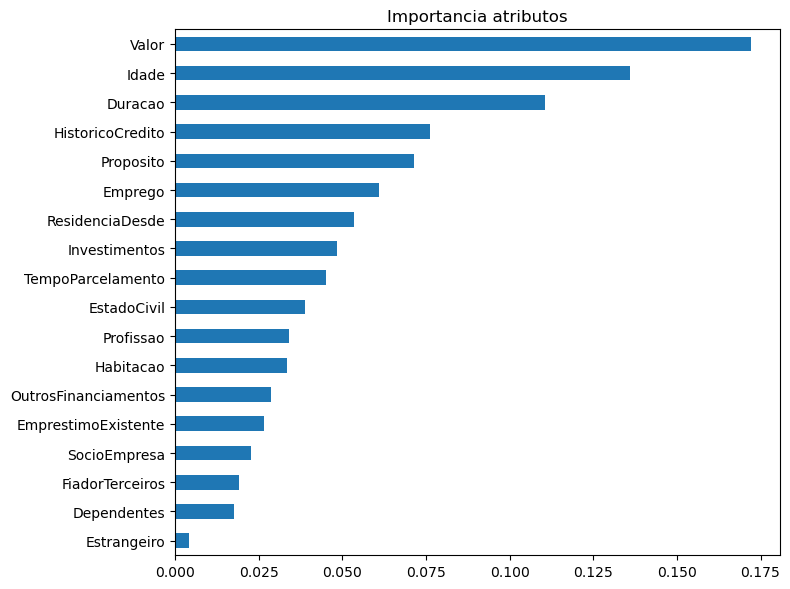

In [20]:
importancias.plot(kind = 'barh', figsize = (8, 6))
plt.title('Importancia atributos')
plt.tight_layout()
plt.show()

In [25]:
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(X_teste)
mask0 = (y_teste == 0)

In [22]:
if isinstance(sv, list):
    sv0 = sv[0]
else:
    sv0 = sv[:, :, 0]

In [26]:
sv0_cls0 = sv0[mask0]
X_cls0 = X_teste[mask0]

In [27]:
shap_importancia0 = pd.Series(np.abs(sv0_cls0).mean(axis=0), index = colunasimp).sort_values(ascending = False)
print(shap_importancia0)

Valor                   0.050862
HistoricoCredito        0.050042
Duracao                 0.047559
Idade                   0.039736
Habitacao               0.025629
EstadoCivil             0.024858
Proposito               0.024478
Investimentos           0.022445
Emprego                 0.020419
OutrosFinanciamentos    0.018140
TempoParcelamento       0.015112
ResidenciaDesde         0.009856
Profissao               0.008199
SocioEmpresa            0.008136
Dependentes             0.006769
EmprestimoExistente     0.005351
FiadorTerceiros         0.004742
Estrangeiro             0.001276
dtype: float64


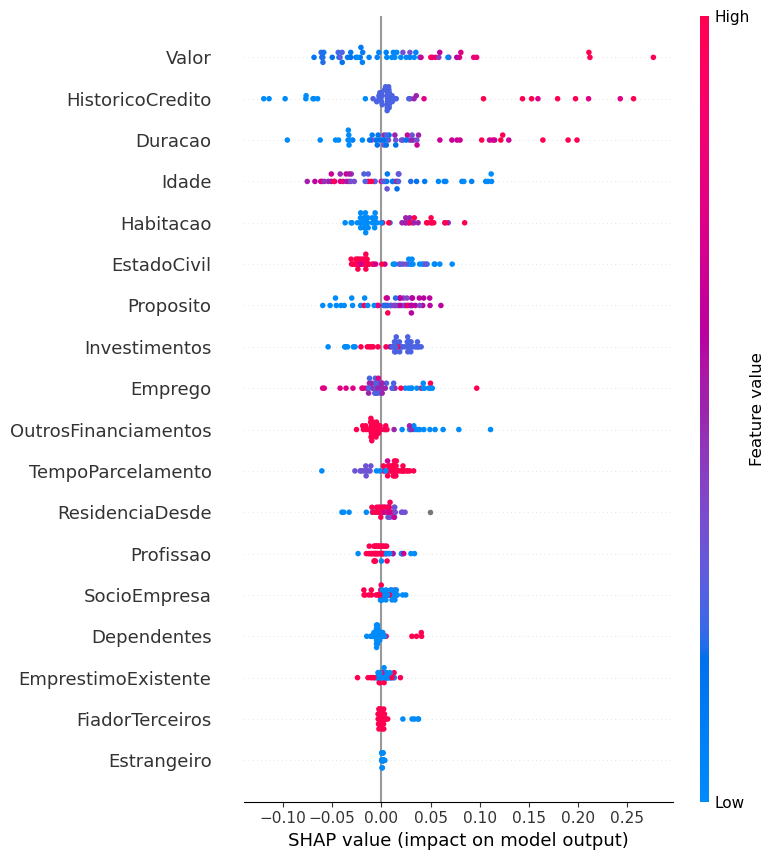

In [28]:
shap.summary_plot(sv0_cls0, X_cls0, feature_names=colunasimp)